# 03 — CLV probabilístico y simulación de estrategias de retención
**Proyecto:** Cadenas de Markov para churn y CLV — MA2004B, ExpoIngenierías AD2026

**Objetivo de este notebook:**
1. Refinar las probabilidades de cancelación (el primer trimestre es distinto del resto del primer año).
2. Calcular el **CLV probabilístico** (valor esperado de ingresos a 5 años) de cada cliente activo.
3. Cuantificar **cuánto valor se espera perder** por cancelaciones.
4. Simular dos estrategias: (A) un programa de retención dirigido por segmento y (B) ofrecer contrato anual a clientes nuevos.
5. Guardar los resultados para el dashboard.

**Idea central:** en vez de predecir *quién* se va, medimos *cuánto vale* cada cliente y *cuánto cuesta* perderlo, para decidir dónde conviene gastar el presupuesto de retención.

## 1. Carga de datos y parámetros

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

RUTA_LOCAL = "../data/processed/telco_estados.csv"
URL_REPO = "https://raw.githubusercontent.com/moonleaal/churn-markov-expoing/main/data/processed/telco_estados.csv"

if os.path.exists(RUTA_LOCAL):
    df = pd.read_csv(RUTA_LOCAL)
else:
    try:
        df = pd.read_csv(URL_REPO)
    except Exception:
        raise FileNotFoundError("No encontré telco_estados.csv. Súbelo al panel de archivos de Colab y ajusta RUTA_LOCAL.")

print("Clientes:", len(df), "| activos:", int((df["churn"] == 0).sum()), "| cancelados:", int(df["churn"].sum()))

Clientes: 7032 | activos: 5163 | cancelados: 1869


### Parámetros del modelo (se pueden cambiar)
| Parámetro | Valor | Significado |
|---|---|---|
| `H` | 60 | Horizonte: 5 años (en meses). Evita extrapolar demasiado más allá de los datos. |
| `TASA_ANUAL` | 10% | Tasa de descuento anual: un peso futuro vale menos que uno de hoy. |
| `MARGEN` | 100% | Fracción de los ingresos que es utilidad. El dataset no trae costos, así que el CLV es de **ingresos**; si la empresa conoce su margen, se cambia aquí. |
| `COSTO_PROGRAMA` | 50 | Costo asumido de inscribir a un cliente en el programa de retención (supuesto, se calibra con la empresa). |
| `REDUCCION` | 20% | Cuánto baja la probabilidad mensual de cancelar con el programa (supuesto, se mide con una prueba A/B). |

> El dataset de IBM no especifica la moneda; los montos se reportan en **dólares (USD)** como supuesto.

In [2]:
H = 60                      # horizonte en meses
TASA_ANUAL = 0.10           # tasa de descuento anual
V = (1 + TASA_ANUAL) ** (-1 / 12)   # factor de descuento mensual
MARGEN = 1.0                # fracción de ingresos que es utilidad
COSTO_PROGRAMA = 50         # costo por cliente inscrito en el programa de retención (USD, supuesto)
REDUCCION = 0.20            # reducción de la prob. de cancelar con el programa (supuesto)

CONTRATOS = ["Mensual", "1 año", "2 años"]

## 2. Probabilidades mensuales de cancelación, ahora en 5 etapas
En el notebook 02 vimos que, en contrato mensual, la cancelación baja mucho dentro del primer año (5.8% al mes en los meses 1–3 contra 1.8% en los meses 10–12). Para no promediar ambos extremos, partimos E1 en dos subetapas:

`E1a` = meses 1–3, `E1b` = meses 4–12, `E2` = 13–24, `E3` = 25–48, `E4` = 49–72.

La estimación es la misma de siempre: cancelaciones entre **meses en riesgo** (así tratamos correctamente a los clientes activos, que son datos censurados).

In [3]:
ETAPAS = ["E1a", "E1b", "E2", "E3", "E4"]
LIMITES = [(1, 3), (4, 12), (13, 24), (25, 48), (49, 72)]

def estimar_hazards(sub):
    filas = []
    for etapa, (a, b) in zip(ETAPAS, LIMITES):
        meses_en_etapa = np.clip(sub["tenure"].values, a - 1, b) - (a - 1)
        meses_en_riesgo = int(meses_en_etapa.sum())
        eventos = int(((sub["churn"] == 1) & (sub["tenure"] >= a) & (sub["tenure"] <= b)).sum())
        filas.append({"etapa": etapa, "eventos": eventos, "meses_en_riesgo": meses_en_riesgo,
                      "q_mensual": eventos / meses_en_riesgo if meses_en_riesgo > 0 else 0.0})
    return pd.DataFrame(filas)

hz = {c: estimar_hazards(df[df["contrato"] == c]) for c in CONTRATOS}
tabla_hz = pd.concat(hz, names=["contrato"]).reset_index(level=0).reset_index(drop=True)
tabla_hz.style.format({"q_mensual": "{:.4f}"})

,contrato,etapa,eventos,meses_en_riesgo,q_mensual
0,Mensual,E1a,595,10187,0.0584
1,Mensual,E1b,429,21308,0.0201
2,Mensual,E2,278,18216,0.0153
3,Mensual,E3,264,16885,0.0156
4,Mensual,E4,89,3296,0.0270
5,1 año,E1a,2,4395,0.0005
6,1 año,E1b,11,12759,0.0009
7,1 año,E2,16,15210,0.0011
8,1 año,E3,55,21826,0.0025
9,1 año,E4,82,7742,0.0106


### Del modelo por etapas a un modelo mes a mes
Cada mes de antigüedad $m$ (1, 2, …) usa la probabilidad $q$ de su etapa. Más allá de los 72 meses (donde ya no hay datos) se mantiene la de E4: es una **extrapolación** que solo afecta a clientes con antigüedad alta (y se declara como limitación).

La probabilidad de que un cliente con $t_0$ meses de antigüedad siga activo $k$ meses después es

$$P(\text{activo}) = \prod_{m=t_0+1}^{t_0+k}(1-q_m)$$

que es exactamente la cadena de Markov mes a mes del notebook 02.

In [4]:
M_MAX = 72 + H + 1   # meses que necesitamos cubrir (datos + extrapolación)

def arreglo_hazard(q_etapas):
    """h[m] = probabilidad de cancelar durante el mes m de antigüedad (m = 1, 2, ...)."""
    h = np.zeros(M_MAX + 1)
    for m in range(1, M_MAX + 1):
        k = next((i for i, (a, b) in enumerate(LIMITES) if a <= m <= b), len(LIMITES) - 1)
        h[m] = q_etapas[k]
    return h

def supervivencia_acumulada(h):
    """cum[m] = probabilidad de que un cliente nuevo siga activo después de m meses."""
    return np.concatenate([[1.0], np.cumprod(1 - h[1:])])

H_BASE = {c: arreglo_hazard(hz[c]["q_mensual"].values) for c in CONTRATOS}

### Validación contra los datos reales (Kaplan–Meier)
Comparamos la supervivencia que predice el modelo refinado con la observada.

In [5]:
def kaplan_meier(sub, T=72):
    S, surv = [1.0], 1.0
    for t in range(1, T + 1):
        en_riesgo = (sub["tenure"] >= t).sum()
        eventos = ((sub["tenure"] == t) & (sub["churn"] == 1)).sum()
        if en_riesgo > 0:
            surv *= 1 - eventos / en_riesgo
        S.append(surv)
    return np.array(S)

filas = []
for c in CONTRATOS:
    KM = kaplan_meier(df[df["contrato"] == c])
    S = supervivencia_acumulada(H_BASE[c])
    for t in [12, 24, 36, 48, 60]:
        filas.append({"contrato": c, "mes": t, "observado": KM[t], "modelo": S[t], "error (pp)": (S[t] - KM[t]) * 100})
val = pd.DataFrame(filas)
display(val.style.format({"observado": "{:.4f}", "modelo": "{:.4f}", "error (pp)": "{:.2f}"}))
print("Error absoluto máximo (puntos porcentuales):", round(val["error (pp)"].abs().max(), 2), "(con el modelo de 5 estados del notebook 02 era ~7)")

,contrato,mes,observado,modelo,error (pp)
0,Mensual,12,0.7031,0.6952,-0.79
1,Mensual,24,0.5859,0.5780,-0.79
2,Mensual,36,0.4911,0.4784,-1.27
3,Mensual,48,0.3973,0.3960,-0.13
4,Mensual,60,0.2972,0.2851,-1.20
5,1 año,12,0.9908,0.9909,0.01
6,1 año,24,0.9783,0.9785,0.02
7,1 año,36,0.9593,0.9493,-1.00
8,1 año,48,0.9165,0.9210,0.44
9,1 año,60,0.8318,0.8105,-2.13


Error absoluto máximo (puntos porcentuales): 2.13 (con el modelo de 5 estados del notebook 02 era ~7)


## 3. CLV probabilístico
El **CLV** de un cliente es el valor esperado de lo que nos pagará en los próximos $H$ meses, tomando en cuenta que puede cancelar en cualquier momento y que un peso futuro vale menos que uno de hoy:

$$\text{CLV}_i = \sum_{k=0}^{H-1} \underbrace{P(\text{activo en el mes } t_0+k+1)}_{\text{cadena de Markov}} \cdot \underbrace{\text{pago mensual}_i \cdot \text{MARGEN}}_{\text{ingreso}} \cdot V^{k}$$

In [6]:
def clv_vector(t0, pago_mensual, h, horizonte=H):
    """CLV esperado de clientes con antigüedad t0 (array) y pago mensual dado, con hazard h."""
    cum = supervivencia_acumulada(h)
    k = np.arange(horizonte)
    prob_activo = cum[t0[:, None] + k] / cum[t0][:, None]      # P(seguir activo | ya sobrevivió t0 meses)
    return pago_mensual * MARGEN * (prob_activo * V ** k).sum(axis=1)

def clv_clientes(sub, mult=1.0):
    """CLV de cada cliente de 'sub' (que trae contrato, tenure, MonthlyCharges). mult escala el hazard."""
    out = pd.Series(0.0, index=sub.index)
    for c in CONTRATOS:
        mk = sub["contrato"] == c
        if mk.any():
            out[mk] = clv_vector(sub.loc[mk, "tenure"].values, sub.loc[mk, "MonthlyCharges"].values, H_BASE[c] * mult)
    return out

# Valor máximo posible: lo que pagaría cada cliente si nadie cancelara
factor_sin_cancelar = (V ** np.arange(H)).sum()

### 3.1 CLV de la base de clientes activos

In [7]:
activos = df[df["churn"] == 0].copy()
activos["etapa"] = pd.cut(activos["tenure"], bins=[0, 3, 12, 24, 48, 72], labels=ETAPAS)
activos["clv"] = clv_clientes(activos)
activos["clv_sin_cancelar"] = activos["MonthlyCharges"] * MARGEN * factor_sin_cancelar

total, potencial = activos["clv"].sum(), activos["clv_sin_cancelar"].sum()
print(f"Clientes activos:                      {len(activos):,}")
print(f"Valor máximo si nadie cancelara (5 a.): ${potencial:,.0f}")
print(f"CLV esperado (con cancelaciones):       ${total:,.0f}")
print(f"Valor que se espera perder:             ${potencial - total:,.0f}  ({100 * (1 - total / potencial):.1f}%)")

Clientes activos:                      5,163
Valor máximo si nadie cancelara (5 a.): $15,167,358
CLV esperado (con cancelaciones):       $11,626,271
Valor que se espera perder:             $3,541,088  (23.3%)


In [8]:
por_contrato = activos.groupby("contrato").agg(
    clientes=("clv", "size"),
    clv_promedio=("clv", "mean"),
    clv_total=("clv", "sum"),
    valor_maximo=("clv_sin_cancelar", "sum"),
).loc[CONTRATOS]
por_contrato["perdida_esperada_%"] = 100 * (1 - por_contrato["clv_total"] / por_contrato["valor_maximo"])
por_contrato

,clientes,clv_promedio,clv_total,valor_maximo,perdida_esperada_%
contrato,,,,,
Mensual,2220,"1,796.75","3,988,776.41","6,538,212.29",38.99
1 año,1306,"2,401.91","3,136,891.83","3,913,833.58",19.85
2 años,1637,"2,749.30","4,500,602.59","4,715,312.59",4.55


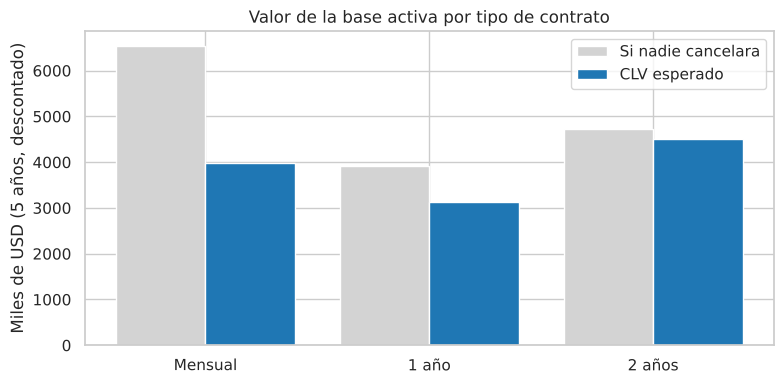

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(CONTRATOS))
ax.bar(x - 0.2, por_contrato["valor_maximo"] / 1e3, width=0.4, label="Si nadie cancelara", color="lightgray")
ax.bar(x + 0.2, por_contrato["clv_total"] / 1e3, width=0.4, label="CLV esperado", color="tab:blue")
ax.set_xticks(x); ax.set_xticklabels(CONTRATOS)
ax.set_ylabel("Miles de USD (5 años, descontado)")
ax.set_title("Valor de la base activa por tipo de contrato")
ax.legend()
plt.tight_layout()
plt.show()

### 3.2 ¿Cuánto vale un cliente nuevo según su contrato?

In [10]:
filas = []
for c in CONTRATOS:
    pago = df.loc[df["contrato"] == c, "MonthlyCharges"].mean()
    valor = clv_vector(np.array([0]), np.array([pago]), H_BASE[c])[0]
    filas.append({"contrato": c, "pago_mensual_promedio": pago, "CLV_cliente_nuevo": valor})
nuevo = pd.DataFrame(filas).set_index("contrato")
nuevo["veces_vs_mensual"] = nuevo["CLV_cliente_nuevo"] / nuevo.loc["Mensual", "CLV_cliente_nuevo"]
nuevo

,pago_mensual_promedio,CLV_cliente_nuevo,veces_vs_mensual
contrato,,,
Mensual,66.40,"1,833.16",1.00
1 año,65.08,"2,982.19",1.63
2 años,60.87,"2,907.99",1.59


**Lectura:** los tres tipos de cliente pagan casi lo mismo al mes, pero el cliente de contrato anual o bianual vale mucho más porque se queda más tiempo. La diferencia de valor sale de la cadena de Markov, no del precio.

## 4. Estrategia A — Programa de retención dirigido por segmento
Un **programa de retención** reduce la probabilidad mensual de cancelar de los clientes inscritos en `REDUCCION` (20%) durante el horizonte. Cuesta `COSTO_PROGRAMA` por cliente.

Para cada segmento (contrato × etapa actual) calculamos cuánto CLV se recupera y si compensa el costo:

$$\text{ROI}=\frac{\Delta\text{CLV por cliente}-\text{costo}}{\text{costo}}$$

In [11]:
filas = []
for (c, e), sub in activos.groupby(["contrato", "etapa"], observed=True):
    base = sub["clv"]
    con_programa = clv_clientes(sub, mult=1 - REDUCCION)
    delta = con_programa - base
    filas.append({"contrato": c, "etapa": e, "clientes": len(sub),
                  "clv_promedio": base.mean(),
                  "delta_clv_por_cliente": delta.mean(),
                  "delta_clv_total": delta.sum(),
                  "costo_total": len(sub) * COSTO_PROGRAMA,
                  # meses del horizonte que caen más allá de los 72 meses con datos (extrapolación)
                  "meses_extrapolados": np.clip(sub["tenure"] + H - 72, 0, H).mean()})
prio = pd.DataFrame(filas)
prio["ganancia_neta"] = prio["delta_clv_total"] - prio["costo_total"]
prio["ROI"] = prio["delta_clv_por_cliente"] / COSTO_PROGRAMA - 1
prio = prio.sort_values("ROI", ascending=False).reset_index(drop=True)
display(prio)
print("Ojo: 'meses_extrapolados' dice cuántos de los 60 meses del horizonte caen fuera del rango con datos (más de 72 meses de antigüedad).")
print("Entre más alto, más depende el resultado del supuesto de que la tasa de E4 se mantiene.")

,contrato,etapa,clientes,clv_promedio,delta_clv_por_cliente,delta_clv_total,costo_total,meses_extrapolados,ganancia_neta,ROI
0,Mensual,E4,253,"2,126.09",252.97,"64,000.97",12650,45.93,"51,350.97",4.06
1,Mensual,E3,538,"2,015.63",195.35,"105,098.58",26900,22.85,"78,198.58",2.91
2,Mensual,E2,459,"1,962.47",160.40,"73,621.78",22950,6.32,"50,671.78",2.21
3,1 año,E4,552,"2,816.62",150.50,"83,078.11",27600,48.22,"55,478.11",2.01
4,Mensual,E1b,540,"1,668.85",135.46,"73,148.42",27000,0.00,"46,148.42",1.71
5,Mensual,E1a,430,"1,312.81",123.70,"53,192.16",21500,0.00,"31,692.16",1.47
6,1 año,E3,463,"2,335.95",90.26,"41,791.90",23150,24.56,"18,641.90",0.81
7,1 año,E2,181,"1,834.57",39.16,"7,088.27",9050,7.02,"-1,961.73",-0.22
8,2 años,E4,1221,"3,066.00",30.48,"37,211.60",61050,53.99,"-23,838.40",-0.39
9,1 año,E1b,92,"1,598.18",22.18,"2,040.55",4600,0.00,"-2,559.45",-0.56


Ojo: 'meses_extrapolados' dice cuántos de los 60 meses del horizonte caen fuera del rango con datos (más de 72 meses de antigüedad).
Entre más alto, más depende el resultado del supuesto de que la tasa de E4 se mantiene.


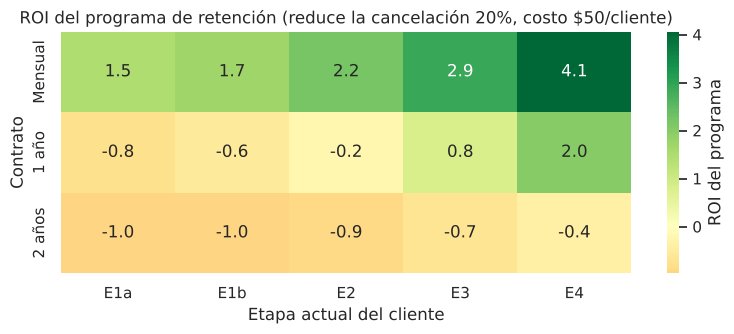

In [12]:
pivote = prio.pivot(index="contrato", columns="etapa", values="ROI").reindex(index=CONTRATOS, columns=ETAPAS)
plt.figure(figsize=(8, 3.5))
sns.heatmap(pivote, annot=True, fmt=".1f", cmap="RdYlGn", center=0, cbar_kws={"label": "ROI del programa"})
plt.title(f"ROI del programa de retención (reduce la cancelación {REDUCCION:.0%}, costo ${COSTO_PROGRAMA}/cliente)")
plt.ylabel("Contrato"); plt.xlabel("Etapa actual del cliente")
plt.tight_layout()
plt.show()

In [13]:
# ¿Aplicarlo a todos o solo donde conviene?
todos = prio["ganancia_neta"].sum()
focalizado = prio.loc[prio["ROI"] > 0, "ganancia_neta"].sum()
inversion_focalizada = prio.loc[prio["ROI"] > 0, "costo_total"].sum()
inversion_todos = prio["costo_total"].sum()

print(f"Aplicar a TODOS los clientes activos:  inversión ${inversion_todos:,.0f}  -> ganancia neta ${todos:,.0f}")
print(f"Aplicar solo a segmentos con ROI > 0:  inversión ${inversion_focalizada:,.0f}  -> ganancia neta ${focalizado:,.0f}")
print(f"Segmentos con ROI > 0: {int((prio['ROI'] > 0).sum())} de {len(prio)}")

Aplicar a TODOS los clientes activos:  inversión $258,150  -> ganancia neta $286,916
Aplicar solo a segmentos con ROI > 0:  inversión $161,750  -> ganancia neta $332,182
Segmentos con ROI > 0: 7 de 15


## 5. Estrategia B — Ofrecer contrato anual a clientes nuevos
Escenario: de cada 1,000 clientes nuevos que habrían tomado contrato **mensual**, una fracción `P_ACEPTA` acepta uno **anual** a cambio de un descuento `DESCUENTO` sobre su pago mensual.

**Supuesto crítico (se declara en el reporte):** que alguien tenga contrato anual *no significa* que el contrato sea la causa de que cancele menos (los clientes que eligen contrato largo ya son más leales). Por eso suponemos que solo una fracción `EFECTIVIDAD` de la diferencia observada entre ambos contratos es efecto real del contrato:

$$h_{\text{nuevo}} = h_{\text{mensual}} + \text{EFECTIVIDAD}\cdot(h_{\text{anual}}-h_{\text{mensual}})$$

Con `EFECTIVIDAD = 1` sería el caso optimista (todo el efecto es causal); con 0.5, solo la mitad. El valor real se mide con una prueba A/B.

In [14]:
N_NUEVOS = 1000      # clientes nuevos que habrían tomado contrato mensual
P_ACEPTA = 0.30      # fracción que acepta el contrato anual
DESCUENTO = 0.15     # descuento sobre el pago mensual
EFECTIVIDAD = 0.50   # fracción de la diferencia mensual-anual que es efecto real del contrato

pago_mensual = df.loc[df["contrato"] == "Mensual", "MonthlyCharges"].mean()
t0 = np.array([0])

def ganancia_por_cliente_convertido(descuento, efectividad):
    h_nuevo = H_BASE["Mensual"] + efectividad * (H_BASE["1 año"] - H_BASE["Mensual"])
    clv_base = clv_vector(t0, np.array([pago_mensual]), H_BASE["Mensual"])[0]
    clv_nuevo = clv_vector(t0, np.array([pago_mensual * (1 - descuento)]), h_nuevo)[0]
    return clv_nuevo - clv_base, clv_base, clv_nuevo

g, clv_base_m, clv_nuevo_m = ganancia_por_cliente_convertido(DESCUENTO, EFECTIVIDAD)
print(f"CLV de un cliente mensual nuevo:                         ${clv_base_m:,.0f}")
print(f"CLV si toma contrato anual (descuento {DESCUENTO:.0%}, efectividad {EFECTIVIDAD:.0%}): ${clv_nuevo_m:,.0f}")
print(f"Ganancia neta por cliente convertido:                    ${g:,.0f}")
print(f"Ganancia neta total ({N_NUEVOS * P_ACEPTA:,.0f} clientes convertidos de {N_NUEVOS:,}):   ${g * N_NUEVOS * P_ACEPTA:,.0f}")

CLV de un cliente mensual nuevo:                         $1,833
CLV si toma contrato anual (descuento 15%, efectividad 50%): $1,995
Ganancia neta por cliente convertido:                    $161
Ganancia neta total (300 clientes convertidos de 1,000):   $48,448


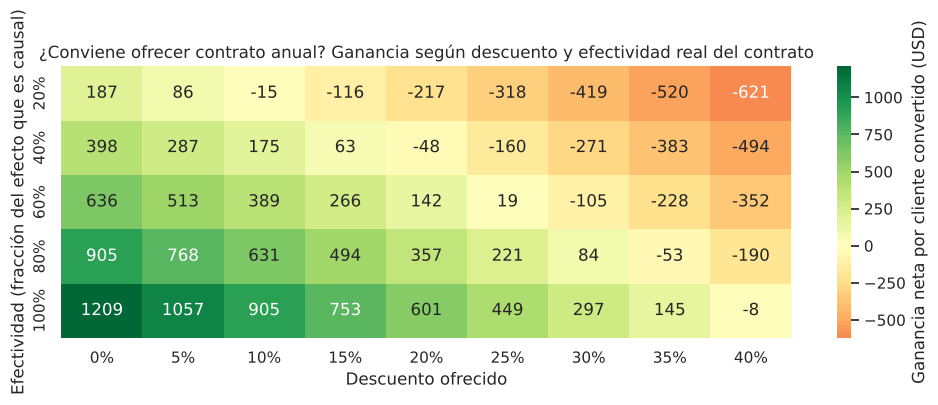

In [15]:
descuentos = np.arange(0, 0.45, 0.05)
efectividades = [0.2, 0.4, 0.6, 0.8, 1.0]

grid = pd.DataFrame(
    [[ganancia_por_cliente_convertido(d, e)[0] for d in descuentos] for e in efectividades],
    index=[f"{e:.0%}" for e in efectividades], columns=[f"{d:.0%}" for d in descuentos])

plt.figure(figsize=(10, 3.8))
sns.heatmap(grid, annot=True, fmt=".0f", cmap="RdYlGn", center=0, cbar_kws={"label": "Ganancia neta por cliente convertido (USD)"})
plt.title("¿Conviene ofrecer contrato anual? Ganancia según descuento y efectividad real del contrato")
plt.xlabel("Descuento ofrecido"); plt.ylabel("Efectividad (fracción del efecto que es causal)")
plt.tight_layout()
plt.show()

In [16]:
# Descuento máximo rentable (ganancia neta = 0) según la efectividad
filas = []
for e in efectividades:
    h_nuevo = H_BASE["Mensual"] + e * (H_BASE["1 año"] - H_BASE["Mensual"])
    clv_base = clv_vector(t0, np.array([pago_mensual]), H_BASE["Mensual"])[0]
    clv_sin_desc = clv_vector(t0, np.array([pago_mensual]), h_nuevo)[0]
    filas.append({"efectividad": f"{e:.0%}", "descuento_maximo_rentable": max(0.0, 1 - clv_base / clv_sin_desc)})
pd.DataFrame(filas).set_index("efectividad").style.format("{:.1%}")

,descuento_maximo_rentable
efectividad,
20%,9.3%
40%,17.8%
60%,25.8%
80%,33.1%
100%,39.8%


## Resultados y lectura de negocio

**1. Cuánto valor está en juego.** De los \$15.17 M que pagarían los 5,163 clientes activos en 5 años (descontado) si nadie cancelara, se espera perder **\$3.54 M (23.3%)**. La pérdida está muy concentrada: **39% en contrato mensual, 19.9% en 1 año y 4.6% en 2 años**.

**2. El contrato vale más que el precio.** Con un pago mensual casi igual, un cliente nuevo de contrato anual vale **1.63 veces** y uno de dos años **1.59 veces** lo que vale uno mensual.

**3. Programa de retención: focalizar gana más que repartir.** Con los supuestos del notebook (reduce la cancelación 20%, cuesta \$50 por cliente):
- Aplicarlo a **todos** los activos: inversión \$258 K → ganancia neta \$287 K.
- Aplicarlo solo a los **7 de 15 segmentos con ROI positivo**: inversión \$162 K → ganancia neta **\$332 K**. Se invierte 37% menos y se gana más.
- Los clientes de **2 años nunca compensan** (el programa recupera entre \$1 y \$30 por cliente contra \$50 de costo): ya casi no cancelan, así que no hay riesgo que reducir.

**4. Advertencia de extrapolación (importante para el reporte).** Los segmentos mejor rankeados, *Mensual E4* y *1 año E4*, tienen clientes con 49–72 meses de antigüedad, así que **46–48 de los 60 meses del horizonte caen fuera del rango con datos** y dependen de suponer que la tasa de E4 se mantiene (con solo 89 cancelaciones observadas en Mensual E4). La recomendación más sólida es la de **contrato mensual en E1a, E1b y E2** (ROI entre 1.5 y 2.2, con 0 a 6 meses extrapolados). E3 queda en un punto intermedio (~23 meses extrapolados).

**5. Ofrecer contrato anual a clientes nuevos: depende del descuento.** Con descuento de 15% y suponiendo que la mitad de la diferencia mensual–anual es efecto real del contrato, la ganancia es de **\$161 por cliente convertido** (\$48 K por cada 1,000 clientes nuevos si acepta el 30%). Pero el **descuento máximo rentable** cambia mucho con ese supuesto:

| Efecto real del contrato | 20% | 40% | 60% | 80% | 100% |
|---|---|---|---|---|---|
| Descuento máximo rentable | 9% | 18% | 26% | 33% | 40% |

Con un efecto real de solo 20%, un descuento de 15% **pierde dinero** (−\$116 por cliente). La oferta solo conviene si el descuento queda por debajo de ese umbral, y el efecto real debe medirse con una **prueba A/B** antes de lanzarla.

**Limitaciones que se declaran en el reporte:** el CLV es de *ingresos* (el dataset no trae costos ni margen); la moneda se asume USD; `REDUCCION`, `COSTO_PROGRAMA` y `EFECTIVIDAD` son supuestos que la empresa debe calibrar; el dataset es una foto fija (no un historial mes a mes); y no se incluyen factores externos como la competencia.


## 6. Guardar resultados para el dashboard

In [17]:
salida_clv = activos[["customerID", "contrato", "etapa", "tenure", "MonthlyCharges", "clv", "clv_sin_cancelar"]]
salida_clv.to_csv("clv_por_cliente.csv", index=False)
tabla_hz.to_csv("hazards_refinados.csv", index=False)
prio.to_csv("prioridad_segmentos.csv", index=False)
print("Guardados: clv_por_cliente.csv, hazards_refinados.csv y prioridad_segmentos.csv")

# En Colab: descarga los archivos a tu computadora (luego se suben a data/processed/ del repo)
try:
    from google.colab import files
    for f in ["clv_por_cliente.csv", "hazards_refinados.csv", "prioridad_segmentos.csv"]:
        files.download(f)
except ImportError:
    pass

Guardados: clv_por_cliente.csv, hazards_refinados.csv y prioridad_segmentos.csv


## Siguiente paso
Con estos tres archivos construimos el **dashboard** (`app/dashboard.py`): el usuario elige el segmento, el porcentaje de reducción y el descuento, y ve cómo cambia el CLV en tiempo real.